# 7000LBSBAI - Programming for Business Analytics
## Week 9 - Code-along: Patterns Over Time, Segments and Your First Regression
### 📋 ANSWER VERSION: for checking code and independent study

---

**Module:** Programming for Business Analytics  
**Week:** 9  
**Time:** About 60 minutes (four blocks, with your tutor)  
**Topics covered:** Time series with resample and rolling averages · Pivot tables of rates · Automating with loops · Linear regression with statsmodels

---

### How to use this notebook

| Symbol | Meaning |
|--------|---------|
| 👀 Watch | Your tutor explains this cell first -> then you run it |
| 🆘 Solution | The answer to an Adapt task, if you get stuck |
| ✍️ Worked example | Code is already written -> run it and study the output |
| ➡️ Your turn | Write or complete the code in this cell |
| 💬 What does it mean? | Write a short interpretation of your results |
| 🤖 AI activity | A guided activity using Gemini in Colab |
| 🔴 Extension | For students who finish early (optional) |
| 📝 Hint/Tip | Some friendly help and advice |

To run a cell: click on it and press **Shift + Enter**.

---

## ⚠️ BEFORE YOU CONTINUE

### Save a copy of this notebook

Make sure your notebook is saved to your Google Drive:
- **File → Save a copy in Drive**
- Name it: `Week9_CodeAlong_Time_Segments_Regression_YourName.ipynb`

---

### Turn off AI-powered in-line completions

Go to **Tools** -> **Settings** -> **AI Assistance**

> Uncheck `☐ Show AI-powered inline completions`  

> Check `☑️ Hide generative AI features`

---
## How this code-along works

The same four-block format: **👀 Watch → Run → ➡️ Adapt → 💬 Interpret**.

- Each block has a **time limit**. When the time is up, we move on together.
- Stuck on an Adapt task? Open the **🆘 solution**, run it, and go straight to the interpretation.
- Finished early? Try the **🔴 Go further** challenge.

---
## This week's four techniques

| Block | Technique | The question it answers |
|---|---|---|
| 1 | **Time series** | How does something change over time? |
| 2 | **Pivot tables of rates** | How do **two** factors combine? |
| 3 | **Loops** | How can I repeat an analysis for many columns quickly? |
| 4 | **Linear regression** | How much does one variable change with another? |

We use two datasets you already know: **BeanHouse** daily sales (Block 1) and **SwiftDeliver** orders (Blocks 2 to 4).

---
## Set up: run this cell

This cell loads both datasets and prepares SwiftDeliver with the Week 8 steps: the cleaning function, the `late` column and distance bands.

In [ ]:
# ✍️ Set up: just run this cell
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf          # new this week: for regression

sns.set_theme(style='whitegrid')

# Import BeanHouse daily sales (Block 1)
beans = pd.read_csv("https://raw.githubusercontent.com/7000lbsbai/7000LBSBAI/main/datasets/beanhouse_daily_sales.csv")
beans['date'] = pd.to_datetime(beans['date'])

# Import SwiftDeliver orders (Blocks 2 to 4)
raw = pd.read_csv("https://raw.githubusercontent.com/7000lbsbai/7000LBSBAI/main/datasets/swiftdeliver_orders.csv")

# SwiftDeliver orders , prepared with the Week 8 steps
def clean_orders(data):
    """Clean SwiftDeliver orders: the Week 6 cleaning steps in one place."""
    data = data.copy()
    data = data.drop_duplicates()
    data['restaurant_type'] = data['restaurant_type'].str.strip().str.title()
    data = data[data['delivery_time_mins'] > 0]
    return data

# Use clean_orders function on the SwiftDeliver data
df = clean_orders(raw)

# Create 'late' column and 'distance_band' column
df['late'] = np.where(df['delivery_time_mins'] > 30, 1, 0)
df['distance_band'] = pd.cut(df['distance_km'], bins=[0, 2, 4, 6, 13], labels=['0-2 km', '2-4 km', '4-6 km', '6+ km'])

# Check all processed correctly
print("Data loaded!")
print(f"BeanHouse: {beans.shape[0]} rows  |  SwiftDeliver: {df.shape[0]} rows")

Data loaded!
BeanHouse: 252 rows  |  SwiftDeliver: 399 rows


---
# Block 1: Patterns over time
*about 15 minutes*

A **time series** is a set of values recorded over time. To work with one in pandas, make the **dates the index** with `.set_index()`. Then:

- `.resample('W').sum()` changes the time scale, e.g. daily values into **weekly** totals (`'ME'` gives monthly totals).
- `.rolling(7).mean()` gives a **7-day rolling average**: the average of each day and the 6 days before it. It smooths out day-to-day ups and downs, so the overall pattern is easier to see.

When you read a time series, look for:

| Pattern | What it looks like |
|---|---|
| **Trend** | A steady rise or fall over the whole period |
| **Cycle** | A pattern that repeats, e.g. every week |
| **One-off** | A single unusual spike or dip |

Weekly revenue (first 4 weeks):
date
2024-04-07    3821.54
2024-04-14    3769.58
2024-04-21    3903.39
2024-04-28    3482.05
Freq: W-SUN, Name: revenue, dtype: float64


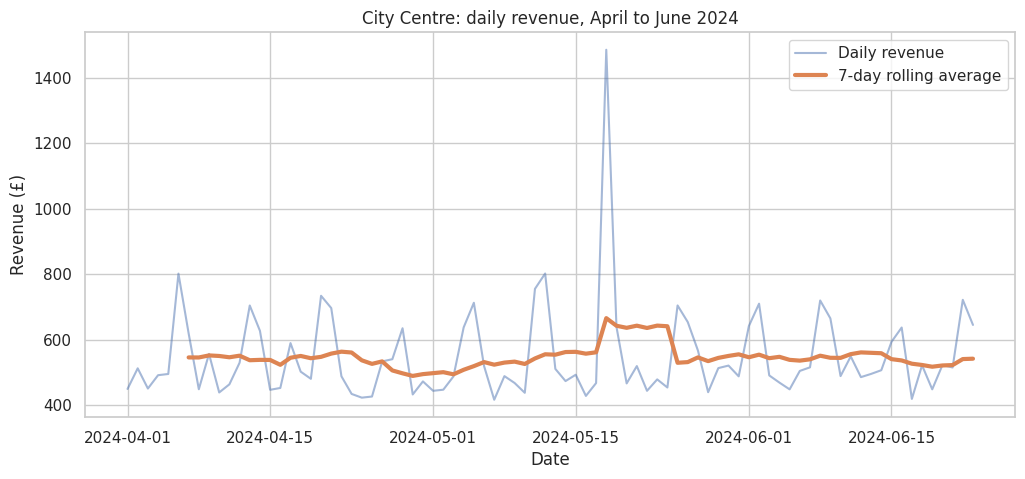

In [ ]:
# 👀 Block 1: City Centre daily revenue as a time series
# Watch the demo first, then run this cell yourself

# 1. One branch, with the dates as the index
city = beans[beans['branch'] == 'City Centre'].set_index('date')['revenue']

# 2. Weekly totals (resample) and a 7-day rolling average
print("Weekly revenue (first 4 weeks):")
print(city.resample('W').sum().head(4).round(2))
rolling_avg = city.rolling(7).mean()

# 3. A line chart of the daily values, with the rolling average on top
plt.figure(figsize=(12, 5))
plt.plot(city.index, city.values, alpha=0.5, label='Daily revenue')
plt.plot(rolling_avg.index, rolling_avg.values, linewidth=3, label='7-day rolling average')
plt.title('City Centre: daily revenue, April to June 2024')
plt.xlabel('Date')
plt.ylabel('Revenue (£)')
plt.legend()
plt.show()

> 📝 The first 6 days of the rolling average are empty as there are not yet 7 days to average.

### ➡️ Adapt: the University branch

Create the same chart for the **University** branch, with a title and axis labels.

> 📝 **Hint:** change `'City Centre'` to `'University'`, and use new variable names (e.g. `uni`, `uni_avg`) so you do not overwrite `city`.

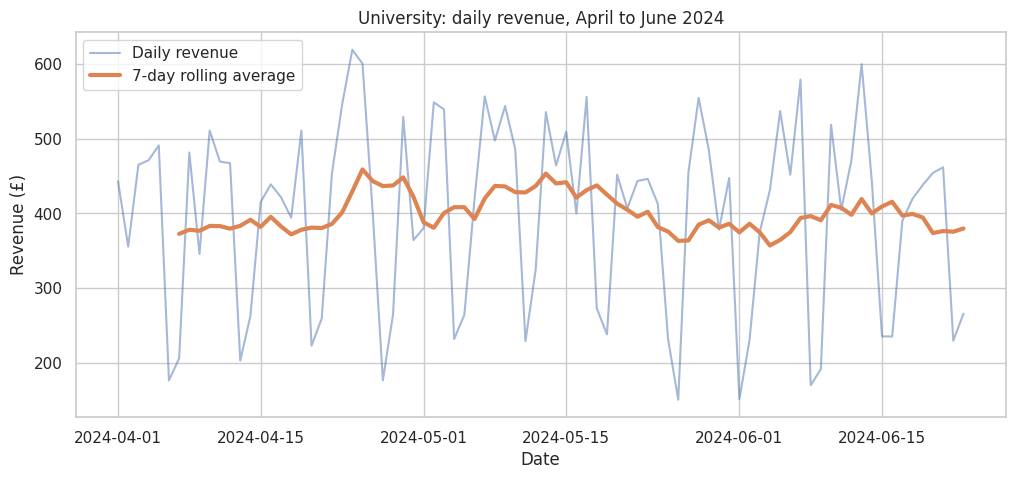

In [ ]:
# ➡️ Adapt: the University branch
uni = beans[beans['branch'] == 'University'].set_index('date')['revenue']
uni_avg = uni.rolling(7).mean()

plt.figure(figsize=(12, 5))
plt.plot(uni.index, uni.values, alpha=0.5, label='Daily revenue')
plt.plot(uni_avg.index, uni_avg.values, linewidth=3, label='7-day rolling average')
plt.title('University: daily revenue, April to June 2024')
plt.xlabel('Date')
plt.ylabel('Revenue (£)')
plt.legend()
plt.show()

# A regular weekly cycle, the other way up: high on weekdays, low at weekends

<details>
<summary><b>🆘 Stuck? Click here for the solution to "the University branch"</b></summary>

Copy this code into the cell above, run it, then move on to the interpretation.

```python
uni = beans[beans['branch'] == 'University'].set_index('date')['revenue']
uni_avg = uni.rolling(7).mean()
plt.figure(figsize=(12, 5))
plt.plot(uni.index, uni.values, alpha=0.5, label='Daily revenue')
plt.plot(uni_avg.index, uni_avg.values, linewidth=3, label='7-day rolling average')
plt.title('University: daily revenue, April to June 2024')
plt.xlabel('Date')
plt.ylabel('Revenue (£)')
plt.legend()
plt.show()
```
</details>

### 💬 What does it mean?

- What patterns can you see in City Centre's revenue: a trend, a cycle, or one-offs?
- How is University's pattern different?
- What does the rolling average show that the daily values do not?

**✏️ MODEL ANSWER:**

City Centre has a clear **weekly cycle**: revenue jumps every weekend (an average of **£712**, against **£481** on weekdays), and there is one **one-off** spike, the festival day in May. That one day lifts the rolling average for a **whole week**, because it is included in every 7-day average that covers it. There is **no real trend**: the rolling average stays at around **£540** from start to finish. University has a weekly cycle the **other way up**: busy on weekdays, quiet at weekends. The rolling average **smooths out** the weekly zigzag, so it is easy to see that neither branch is growing or shrinking over the 12 weeks.

### 🔴 Go further: all three branches together

Add up the revenue of **all three branches** for each day (`beans.groupby('date')['revenue'].sum()`), then chart it with a 7-day rolling average. What happens to the weekly cycle?

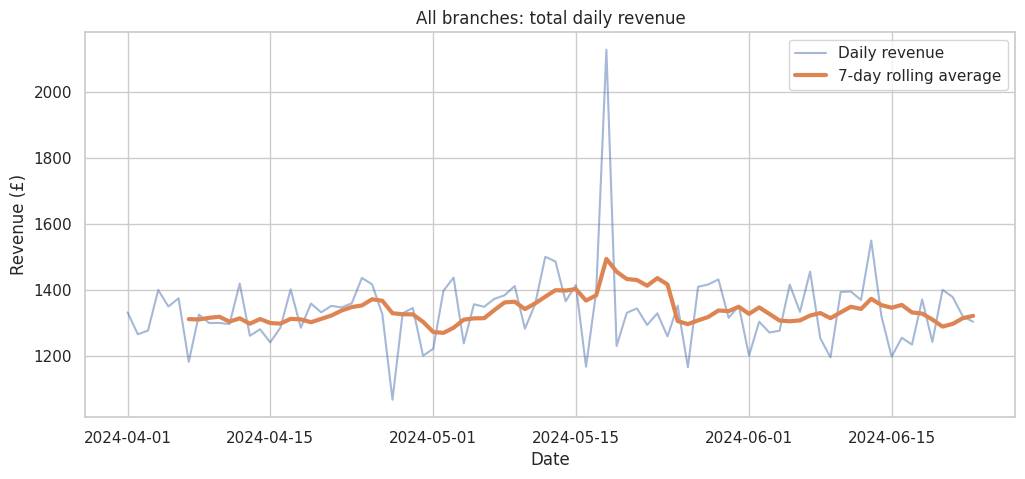

In [ ]:
# 🔴 Go further: all three branches together
total = beans.groupby('date')['revenue'].sum()

plt.figure(figsize=(12, 5))
plt.plot(total.index, total.values, alpha=0.5, label='Daily revenue')
plt.plot(total.index, total.rolling(7).mean().values, linewidth=3, label='7-day rolling average')
plt.title('All branches: total daily revenue')
plt.xlabel('Date')
plt.ylabel('Revenue (£)')
plt.legend()
plt.show()

# The weekly cycle almost disappears: City Centre's busy weekends and University's quiet
# weekends cancel each other out (weekday average £1,348, weekend £1,315).
# Hidden groups again (Week 5): always look at the groups as well as the total

---
# Block 2: Two factors at once
*about 15 minutes*

In Week 8 you compared rates for **one** factor at a time. A **pivot table** compares rates across **two** factors at once: one in the rows, one in the columns.

```python
df.pivot_table(values='late', index='distance_band', columns='weather', aggfunc='mean')
```

The mean of a 1/0 column is a rate, so each cell is a late rate. A **heatmap** of the table makes the pattern easy to see.

> 📝 You met pivot tables in DataCamp. `observed=True` tells pandas to only show categories that actually appear in the dataset and also stops a warning about the bands.

weather         Dry   Rain
distance_band             
0-2 km          1.0    2.7
2-4 km          4.6   38.3
4-6 km         43.9  100.0
6+ km          93.5  100.0

weather        Dry  Rain
distance_band           
0-2 km         100    37
2-4 km         108    47
4-6 km          41    23
6+ km           31    12


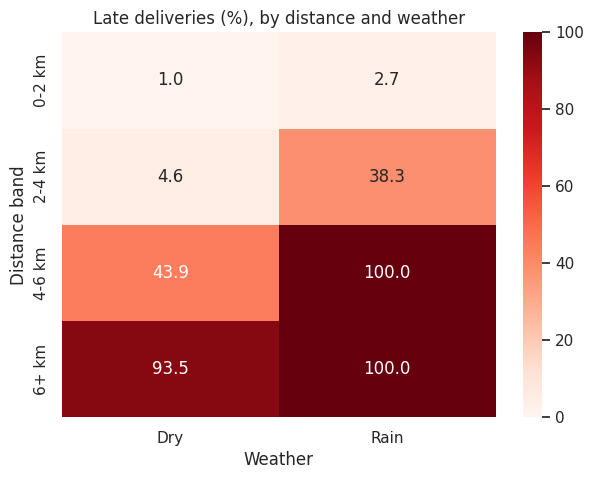

In [ ]:
# 👀 Block 2: the late rate by distance band and weather
# Watch the demo first, then run this cell yourself

# 1. The late rate (%) for each combination of distance band and weather
rates = df.pivot_table(values='late', index='distance_band', columns='weather', aggfunc='mean', observed=True) * 100
print(rates.round(1))
print()

# 2. How many orders is each rate based on? (aggfunc='count')
counts = df.pivot_table(values='late', index='distance_band', columns='weather', aggfunc='count', observed=True)
print(counts)

# 3. A heatmap of the rates
plt.figure(figsize=(7, 5))
sns.heatmap(rates, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100)
plt.title('Late deliveries (%), by distance and weather')
plt.xlabel('Weather')
plt.ylabel('Distance band')
plt.show()

> 📝 `fmt='.1f'` shows each value to 1 decimal place. `vmin=0, vmax=100` keeps the colour scale from 0% to 100%.

### ➡️ Adapt: restaurant type and weather

Create the same table and heatmap for **restaurant type** and **weather**. Print the counts too.

> 📝 **Hint:** change `index='distance_band'` to `index='restaurant_type'`. You do not need `observed=True` for a text column.

weather           Dry  Rain
restaurant_type            
Asian            16.4  48.3
Burger           16.7  39.5
Dessert          17.2  71.4
Healthy          25.7  40.0
Pizza            20.8  45.7

weather          Dry  Rain
restaurant_type           
Asian             67    29
Burger            72    38
Dessert           29     7
Healthy           35    10
Pizza             77    35


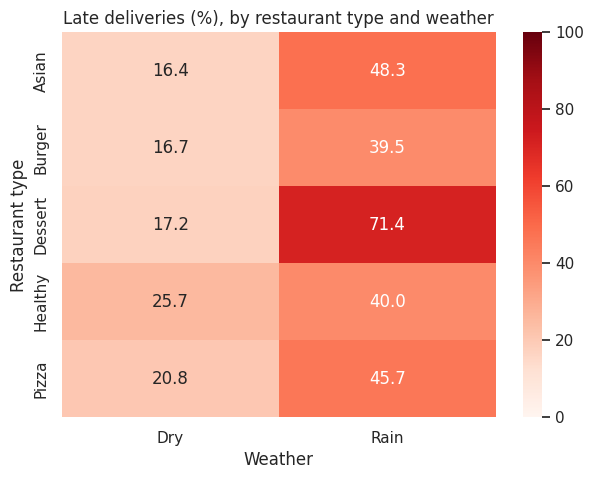

In [ ]:
# ➡️ Adapt: restaurant type and weather
rates_type = df.pivot_table(values='late', index='restaurant_type', columns='weather', aggfunc='mean') * 100
print(rates_type.round(1))
print()
print(df.pivot_table(values='late', index='restaurant_type', columns='weather', aggfunc='count'))

plt.figure(figsize=(7, 5))
sns.heatmap(rates_type, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100)
plt.title('Late deliveries (%), by restaurant type and weather')
plt.xlabel('Weather')
plt.ylabel('Restaurant type')
plt.show()

# Rain raises the late rate for every type. Dessert in the rain looks worst (71.4%),
# but it is based on very few orders

<details>
<summary><b>🆘 Stuck? Click here for the solution to "restaurant type and weather"</b></summary>

Copy this code into the cell above, run it, then move on to the interpretation.

```python
rates_type = df.pivot_table(values='late', index='restaurant_type', columns='weather', aggfunc='mean') * 100
print(rates_type.round(1))
print()
print(df.pivot_table(values='late', index='restaurant_type', columns='weather', aggfunc='count'))
plt.figure(figsize=(7, 5))
sns.heatmap(rates_type, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100)
plt.title('Late deliveries (%), by restaurant type and weather')
plt.xlabel('Weather')
plt.ylabel('Restaurant type')
plt.show()
```
</details>

### 💬 What does it mean?

- How do distance and weather combine?
- Which cells would you not trust much, and why?
- Which restaurant type looks worst in the rain? Should SwiftDeliver act on that?

**✏️ MODEL ANSWER:**

Distance and weather **combine**: the effect of rain is biggest at **medium distances**. For 2-4 km, only **4.6%** of dry-weather deliveries are late, but **38.3%** in the rain. At 4-6 km, **every** rainy-day delivery was late. The cells for long distances in the rain are based on **very few orders** (23 and 12), so they are less reliable, which is why we print the counts. Dessert looks worst in the rain (**71.4%**), but very few dessert orders were delivered in the rain, so this could easily be chance: the pattern across **all** types (rain makes every type later) is the real finding.

### 🔴 Go further: add the totals

Add `margins=True` to the first pivot table. What do the **All** row and column show?

In [ ]:
# 🔴 Go further: add the totals
(df.pivot_table(values='late', index='distance_band', columns='weather', aggfunc='mean', observed=True, margins=True) * 100).round(1)

# The All column gives the late rate for each distance band, the All row for each weather,
# and the bottom-right corner the overall late rate (26.8%)

weather,Dry,Rain,All
distance_band,,,
0-2 km,1.0,2.7,1.5
2-4 km,4.6,38.3,14.8
4-6 km,43.9,100.0,64.1
6+ km,93.5,100.0,95.3
All,18.9,45.4,26.8


---
# Block 3: Automating with loops
*about 15 minutes*

In Week 8 you wrote the same rate code for several columns. A **`for` loop** (Week 1) can do it for you: the code inside the loop runs once for **each** item in a list.

Combined with `plt.subplots()` (Week 5), a loop can draw a whole set of charts at once.

`sharey=True` ensures that all subplots in the figure share the exact same y-axis scale and limits.

`zip()` pairs each chart position with a column name.

weather
Dry     18.9
Rain    45.4
Name: late, dtype: float64

restaurant_type
Asian      26.0
Burger     24.5
Dessert    27.8
Healthy    28.9
Pizza      28.6
Name: late, dtype: float64

distance_band
0-2 km     1.5
2-4 km    14.8
4-6 km    64.1
6+ km     95.3
Name: late, dtype: float64



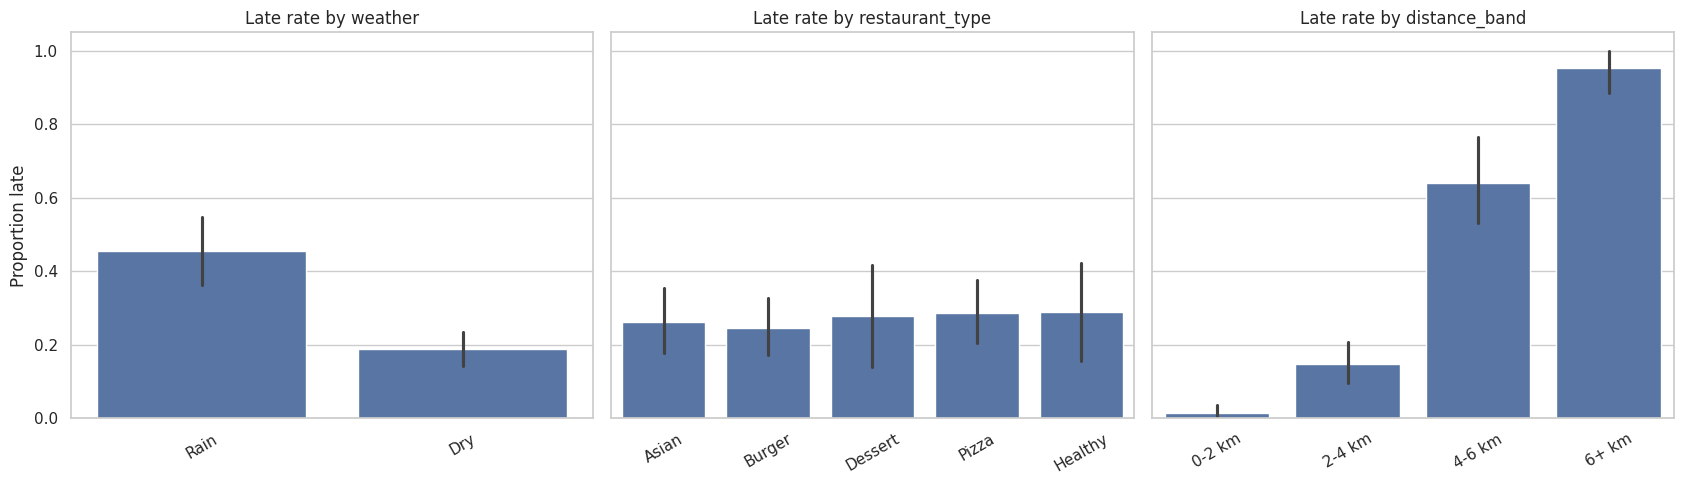

In [ ]:
# 👀 Block 3: a rate table and chart for several columns, with one loop
# Watch the demo first, then run this cell yourself

columns = ['weather', 'restaurant_type', 'distance_band']

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)

for ax, col in zip(axes, columns):
    # 1. Print the late rate (%) for each group in this column
    print((df.groupby(col, observed=True)['late'].mean() * 100).round(1))
    print()

    # 2. Draw a bar chart for this column in its own position
    sns.barplot(data=df, x=col, y='late', ax=ax)
    ax.set_title(f'Late rate by {col}')
    ax.set_xlabel('')
    ax.set_ylabel('Proportion late')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

> 📝 Everything **indented** under `for` runs once per column. The f-string in `set_title` puts each column's name into its title.

### ➡️ Adapt: summarise several columns

Write a loop that prints the **mean** and **median** of each of these columns: `delivery_time_mins`, `order_value`, `tip` and `distance_km`.

> 📝 **Hint:** `for col in [...]:` then, indented, one `print()` with an f-string. Use `df[col]` so the same line works for every column.

In [ ]:
# ➡️ Adapt: summarise several columns
for col in ['delivery_time_mins', 'order_value', 'tip', 'distance_km']:
    print(f"{col}: mean {df[col].mean():.2f}, median {df[col].median():.2f}")

# delivery_time_mins: mean 26.18, median 24.00 ... For every column the mean is above the
# median: all four are right-skewed

delivery_time_mins: mean 26.18, median 24.00
order_value: mean 27.55, median 26.06
tip: mean 2.00, median 1.81
distance_km: mean 3.24, median 2.80


<details>
<summary><b>🆘 Stuck? Click here for the solution to "summarise several columns"</b></summary>

Copy this code into the cell above, run it, then move on to the interpretation.

```python
for col in ['delivery_time_mins', 'order_value', 'tip', 'distance_km']:
    print(f"{col}: mean {df[col].mean():.2f}, median {df[col].median():.2f}")
```
</details>

### 💬 What does it mean?

- Why is a loop better than copying the same code for each column?
- What should you always check after a loop has run?

**✏️ MODEL ANSWER:**

A loop writes the analysis **once**, so it is shorter, and any change (a new title, a different chart) only needs making in one place. It also makes it easy to add more columns: just add them to the list. After a loop runs, **check the output**: is there a result for every column? Do the numbers make sense? (For example, the weather rates match Week 8: 18.9% and 45.4%.) A loop repeats mistakes as quickly as it repeats good code.

### 🔴 Go further: a rate table function inside a loop

Write a function `rate_table(data, column)` that returns the count and the late rate (%) for each group, highest rate first. Then use a loop to print it for `weather`, `restaurant_type` and `distance_band`.

In [ ]:
# 🔴 Go further: a rate table function inside a loop
def rate_table(data, column):
    """Count and late rate (%) for each group in a column, highest rate first."""
    table = data.groupby(column, observed=True)['late'].agg(['count', 'mean'])
    table['late_%'] = (table['mean'] * 100).round(1)
    return table[['count', 'late_%']].sort_values('late_%', ascending=False)

for col in ['weather', 'restaurant_type', 'distance_band']:
    print(rate_table(df, col))
    print()

         count  late_%
weather               
Rain       119    45.4
Dry        280    18.9

                 count  late_%
restaurant_type               
Healthy             45    28.9
Pizza              112    28.6
Dessert             36    27.8
Asian               96    26.0
Burger             110    24.5

               count  late_%
distance_band               
6+ km             43    95.3
4-6 km            64    64.1
2-4 km           155    14.8
0-2 km           137     1.5



---
# Block 4: Adding a regression model
*about 15 minutes*

In Week 6, `sns.regplot()` drew a trend line. That line is a **linear regression**, and it has an equation:

**delivery time = intercept + slope × distance**

`statsmodels` works out the equation for you, and tells you how reliable it is. You know the theory from your Research Methods in Analytics module; here you will **fit** a model in Python and **read** the output.

```python
model = smf.ols('delivery_time_mins ~ distance_km', data=df).fit()
```

Read `~` as *"is explained by"*: delivery time is explained by distance.

`ols` stands for **ordinary least squares**, the standard method.

The full `.summary()` is long. For now, you only need **four things**:

| What | Where | What it tells you |
|---|---|---|
| **Coefficient** (slope) | `model.params` | How much the outcome changes for each extra unit |
| **p-value** | `model.pvalues` | Below 0.05: the relationship is unlikely to be due to chance |
| **R²** | `model.rsquared` | The share of the variation the model explains (0 to 1) |
| **Plain English** | You! | What it means for the business |

In [ ]:
# 👀 Block 4: a linear regression of delivery time on distance
# Watch the demo first, then run this cell yourself

# 1. Fit the model: delivery time is explained by distance
model = smf.ols('delivery_time_mins ~ distance_km', data=df).fit()

# 2. The full output (long: we only need a few numbers from it)
print(model.summary())

# 3. The four things to read
intercept = model.params['Intercept']
coefficient = model.params['distance_km']
pvalue = model.pvalues['distance_km']
rsquared = model.rsquared
print()
print(f"Intercept:   {intercept:.2f} minutes")
print(f"Coefficient: {coefficient:.2f} minutes per km")
print(f"p-value:     {pvalue:.4f}")
print(f"R-squared:   {rsquared:.2f}")

# 4. Use the model to predict delivery times for 2 km and 5 km
new = pd.DataFrame({'distance_km': [2, 5]})
print("\n",model.predict(new).round(1))

# 5. Calculate the distance after which a deliver is expected to be late
print(f"\nExpected late delivery distance: {(30 - intercept)/coefficient:.1f} km")

                            OLS Regression Results                            
Dep. Variable:     delivery_time_mins   R-squared:                       0.744
Model:                            OLS   Adj. R-squared:                  0.743
Method:                 Least Squares   F-statistic:                     1152.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):          1.91e-119
Time:                        12:10:45   Log-Likelihood:                -1178.4
No. Observations:                 399   AIC:                             2361.
Df Residuals:                     397   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      14.7692      0.409     36.131      

> 📝 In the summary, find the same numbers: the `coef` column, the `P>|t|` column and `R-squared` at the top right.
>
> A p-value shown as `0.000` means it is smaller than 0.0005, not exactly zero.
>
> Use of `"\n"` in a print statement adds an extra line; an alternative to using a separate `print()` line to space outputs.

### ➡️ Adapt: tip and order value

Fit a model of `tip` explained by `order_value`. Print the coefficient, its p-value and R², each with an f-string. (You do not need the full summary.)

> 📝 **Hint:** the same as the Watch cell, with `'tip ~ order_value'`. Use a new name, e.g. `tip_model`, so you don't overwrite the first model.

In [ ]:
# ➡️ Adapt: tip and order value
tip_model = smf.ols('tip ~ order_value', data=df).fit()

coefficient = tip_model.params['order_value']
pvalue = tip_model.pvalues['order_value']
rsquared = tip_model.rsquared

print(f"Coefficient: £{coefficient:.2f} per £1 of order value")
print(f"p-value:     {pvalue:.4f}")
print(f"R-squared:   {rsquared:.2f}")

# About 7p of tip per £1 of order value; p well below 0.05; R² = 0.30

Coefficient: £0.07 per £1 of order value
p-value:     0.0000
R-squared:   0.30


<details>
<summary><b>🆘 Stuck? Click here for the solution to "tip and order value"</b></summary>

Copy this code into the cell above, run it, then move on to the interpretation.

```python
tip_model = smf.ols('tip ~ order_value', data=df).fit()
coefficient = tip_model.params['order_value']
pvalue = tip_model.pvalues['order_value']
rsquared = tip_model.rsquared
print(f"Coefficient: £{coefficient:.2f} per £1 of order value")
print(f"p-value:     {pvalue:.4f}")
print(f"R-squared:   {rsquared:.2f}")
```
</details>

### 💬 What does it mean?

- Explain the distance coefficient in plain English. At about what distance does the model predict a delivery will be late (over 30 minutes)?
- What does R² tell you about each model?
- What can these models not tell you?

**✏️ MODEL ANSWER:**

Each extra **kilometre** adds about **3.5 minutes** to a delivery (coefficient 3.52, p well below 0.05). The model predicts **21.8 minutes** for 2 km and **32.3 minutes** for 5 km: a delivery is expected to be late beyond about **4.3 km**, which matches the jump in late rates between the 2-4 km and 4-6 km bands in Week 8. R² is **0.74**: distance explains about three-quarters of the variation in delivery times, so it is a strong single predictor. For tips, each extra £1 of order value adds about **7p** of tip, but R² is only **0.30**, so most of the variation in tips is due to other things. These models use **one** predictor each, so they cannot separate the effects of several factors (for example, distance **and** rain), and, like correlation, they show **association, not cause**. Next week you will add more predictors.

### 🔴 Go further: see the line

Draw a scatter plot of delivery time against distance with `sns.regplot()`, then use `plt.axhline(30, ...)` (similar to `plt.axvline()` that we have used before) to add a horizontal dashed line at the 30-minute limit. Where does the regression line cross it?

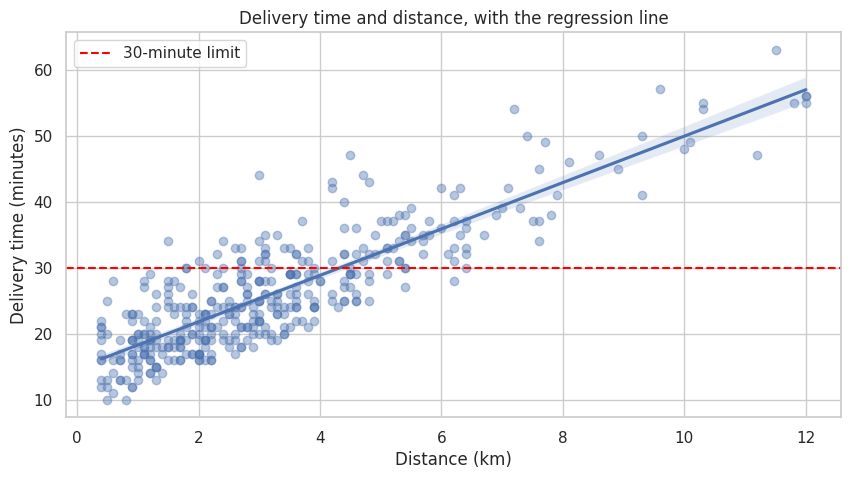

In [ ]:
# 🔴 Go further: see the line
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='distance_km', y='delivery_time_mins', scatter_kws={'alpha': 0.4})
plt.axhline(30, color='red', linestyle='--', label='30-minute limit')
plt.title('Delivery time and distance, with the regression line')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery time (minutes)')
plt.legend()
plt.show()

# The line crosses 30 minutes at about 4.3 km: (30 - 14.77) / 3.52

---
## ✅ End of Code-along: Recap

You have learned four new techniques:

| Technique | Code |
|---|---|
| A time series | `data.set_index('date')['col']` |
| Change the time scale | `.resample('W').sum()` · `'ME'` for months |
| Smooth it | `.rolling(7).mean()` |
| Two factors at once | `df.pivot_table(values=..., index=..., columns=..., aggfunc='mean')` |
| Repeat for many columns | `for col in [...]:` · `zip(axes, columns)` |
| A linear regression | `smf.ols('y ~ x', data=df).fit()` · `.params` · `.pvalues` · `.rsquared` |

---

### 💾 Before you leave

Make sure your notebook is saved to your Google Drive, if you have not done so already:
- **File → Save a copy in Drive**
- Name it: `Week9_CodeAlong_Time_Segments_Regression_YourName.ipynb`

---

### 🔮 Next: the Week 9 task

After the break, you will use all four on the **FitLife** data, and use **Gemini as an assistant**.